# Notebook 03: Model Training, Hyperparameter Tuning & Final Evaluation (RQ2)

**Project:** Development of an AI/ML Model for Identifying Patterns in Road Traffic Accidents  
**Objective 2 (RQ2):** *Train and tune Random Forest, XGBoost, and Multilayer Perceptron models and compare them with a Decision Tree baseline using stratified cross-validation, Macro-F1, recall for fatal and serious classes, and ROC-AUC.*

### Purpose of This Notebook
This notebook implements **Objective 2** of Chapter 3:
1. **Leakage-Safe Modeling Pipeline**: Wrapping temporal feature extraction, fold-safe imputation, ordinal/one-hot encoding, and feature scaling into a unified `scikit-learn` pipeline.
2. **Hyperparameter Tuning**: Tuning all **4 thesis models** (**Decision Tree** baseline, **Random Forest**, **XGBoost**, and **Multilayer Perceptron [MLP]**) on the Training set using 5-fold Group-Stratified Cross-Validation optimizing **Macro-F1**.
3. **Repeated Cross-Validation Comparison (RQ2)**: Comparing the tuned models across 10 group-stratified folds (5 folds × 2 repeats) and checking overfitting gaps.
4. **Validation Check & Binary Fallback Benchmark**: Checking performance on the 15% Validation split and running the documented **Section 3.2.4 Binary Fallback (`Fatal + Serious` vs. `Slight`)** comparison.
5. **Final Held-Out Test Set Evaluation**: Evaluating the winning model **once** on the untouched **15% Test Set** with Confusion Matrices, One-vs-Rest ROC curves, and Precision-Recall curves, then saving the trained pipeline to `models/best_model_bundle.joblib`.

## 1. Setup & Load Fixed Data Splits
We load the exact `train_split.csv` (70%), `val_split.csv` (15%), and `test_split.csv` (15%) created in Notebook 02 so all experiments share identical data partitions.

In [1]:
import json
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import RandomOverSampler
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
     ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import ParameterSampler, StratifiedGroupKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    ORDINAL_MAPS,
    SEVERITY_MAP,
    SEVERITY_ORDER,
    TARGET_COL,
    OrdinalCategoryMapper,
    TemporalFeatureExtractor,
    evaluate_multiclass,
)

sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
RANDOM_STATE = 42

FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TAB_DIR = PROJECT_ROOT / "outputs" / "tables"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
MOD_DIR = PROJECT_ROOT / "models"
MOD_DIR.mkdir(parents=True, exist_ok=True)

# Load fixed 70:15:15 splits and feature schema from Notebook 02
train_df = pd.read_csv(PROC_DIR / "train_split.csv")
val_df = pd.read_csv(PROC_DIR / "val_split.csv")
test_df = pd.read_csv(PROC_DIR / "test_split.csv")
schema = json.loads((PROC_DIR / "feature_schema.json").read_text())

numeric_cols = schema["numeric_cols"]
ordinal_cols = schema["ordinal_cols"]
nominal_cols = schema["nominal_cols"]

raw_predictor_cols = [c for c in train_df.columns if c not in [TARGET_COL, "crash_event_id"]]

X_train_raw = train_df[raw_predictor_cols].copy()
y_train = train_df[TARGET_COL].map(SEVERITY_MAP).values
groups_train = train_df["crash_event_id"].values

X_val_raw = val_df[raw_predictor_cols].copy()
y_val = val_df[TARGET_COL].map(SEVERITY_MAP).values

X_test_raw = test_df[raw_predictor_cols].copy()
y_test = test_df[TARGET_COL].map(SEVERITY_MAP).values

print(f"Train: {X_train_raw.shape} | Validation: {X_val_raw.shape} | Test: {X_test_raw.shape}")

Train: (8620, 24) | Validation: (1867, 24) | Test: (1829, 24)


**Data Splits Loaded:**  
All 24 raw pre-crash predictors are ready across the Train, Validation, and Test splits. Remember that the Test set (`X_test_raw`, `y_test`) remains untouched until Section 5.

---
## 2. Build Unified Leakage-Safe Preprocessing Pipeline
We construct a reusable `build_preprocessor()` function that:
1. Extracts `Hour`, `Time_of_day`, `Is_rush_hour`, and `Is_weekend` (and drops raw `Time`).
2. Imputes and standardizes numerical and ordinal attributes.
3. Imputes and one-hot encodes nominal attributes (`handle_unknown='ignore'`).

Based on our RQ1 findings in Notebook 02—where **Class Weighting** strongly improved recall on rare `Serious` and `Fatal` crashes while preserving real training records—we pair all four candidate models with balanced class/sample weights during tuning and cross-validation.

In [2]:
def build_preprocessor() -> Pipeline:
    """Create a fresh fold-safe preprocessing pipeline."""
    col_transformer = ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline([
                    ("imp", SimpleImputer(strategy="median")),
                    ("scale", StandardScaler()),
                ]),
                numeric_cols,
            ),
            (
                "ord",
                Pipeline([
                    ("map", OrdinalCategoryMapper()),
                    ("scale", StandardScaler()),
                ]),
                ordinal_cols,
            ),
            (
                "nom",
                Pipeline([
                    ("imp", SimpleImputer(strategy="most_frequent")),
                    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
                ]),
                nominal_cols,
            ),
        ],
        verbose_feature_names_out=False,
    )
    return Pipeline([
        ("temporal", TemporalFeatureExtractor()),
        ("encode", col_transformer),
    ])


# Helper to fit any (preprocessor + classifier) pipeline with balanced class/sample weights
def fit_weighted_pipeline(pipe: Pipeline, X_df: pd.DataFrame, y_arr: np.ndarray):
    clf_step = pipe.named_steps["clf"]
    if isinstance(clf_step, XGBClassifier):
        sw = compute_sample_weight(class_weight="balanced", y=y_arr)
        pipe.fit(X_df, y_arr, clf__sample_weight=sw)
    elif isinstance(clf_step, MLPClassifier):
        # Balance classes inside the training fold for mini-batch Adam updates in MLPClassifier
        Xt = pipe.named_steps["prep"].fit_transform(X_df, y_arr)
        Xt_bal, y_bal = RandomOverSampler(random_state=RANDOM_STATE).fit_resample(Xt, y_arr)
        clf_step.fit(Xt_bal, y_bal)
    else:
        pipe.fit(X_df, y_arr)
    return pipe

---
## 3. Hyperparameter Tuning of the Four Thesis Models (Stratified 5-Fold CV)
Following Table 3.2 of Chapter 3, we tune each of the **4 candidate models** using randomized search (`n_iter = 10` candidate configurations per model, or full grid where smaller) over **5-fold Group-Stratified Cross-Validation** on the Training set, selecting hyperparameters that maximize **Macro-F1**:
1. **Decision Tree** *(Interpretable Baseline)*
2. **Random Forest** *(Bagging Ensemble)*
3. **XGBoost** *(Gradient-Boosted Trees)*
4. **Multilayer Perceptron (`MLPClassifier`)** *(Feedforward Neural Network with L2 regularization & early stopping)*

In [3]:
# Define candidate models and hyperparameter search spaces aligned with Chapter 3 (Table 3.2)
model_spaces = {
    "Decision Tree": (
        DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
        {
            "criterion": ["gini", "entropy"],
            "max_depth": [4, 6, 8, 10, 14],
            "min_samples_split": [2, 5, 10, 20],
            "min_samples_leaf": [2, 5, 10],
        },
        12,
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1),
        {
            "n_estimators": [150, 250, 350],
            "max_depth": [6, 8, 10, 14],
            "max_features": ["sqrt", "log2", 0.3],
            "min_samples_leaf": [4, 8, 15],
        },
        10,
    ),
    "XGBoost": (
        XGBClassifier(
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        ),
        {
            "n_estimators": [150, 250, 350],
            "learning_rate": [0.02, 0.05, 0.1],
            "max_depth": [3, 5, 7],
            "subsample": [0.7, 0.85, 1.0],
            "colsample_bytree": [0.7, 0.85, 1.0],
            "min_child_weight": [1, 3, 5],
        },
        10,
    ),
    "MLP": (
        MLPClassifier(
            max_iter=120,
            early_stopping=True,
            n_iter_no_change=8,
            random_state=RANDOM_STATE,
        ),
        {
            "hidden_layer_sizes": [(64,), (128, 64), (256, 128, 64)],
            "activation": ["relu", "tanh"],
            "alpha": [1e-4, 1e-3, 1e-2, 5e-2],
            "learning_rate_init": [1e-3, 3e-3],
        },
        8,
    ),
}

sgkf_tune = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
tune_folds = list(sgkf_tune.split(X_train_raw, y_train, groups=groups_train))

best_configs = {}
tuning_summary_rows = []

for model_name, (base_clf, param_space, n_iter) in model_spaces.items():
    candidates = list(ParameterSampler(param_space, n_iter=n_iter, random_state=RANDOM_STATE))
    best_score = -1.0
    best_params = None
    best_train_score = None

    for params in candidates:
        fold_val_scores = []
        fold_tr_scores = []

        for tr_i, va_i in tune_folds:
            clf_i = clone(base_clf).set_params(**params)
            pipe_i = Pipeline([("prep", build_preprocessor()), ("clf", clf_i)])
            fit_weighted_pipeline(pipe_i, X_train_raw.iloc[tr_i], y_train[tr_i])

            # Record both train and validation Macro-F1 to monitor overfitting
            tr_pred = pipe_i.predict(X_train_raw.iloc[tr_i])
            va_pred = pipe_i.predict(X_train_raw.iloc[va_i])
            fold_tr_scores.append(f1_score(y_train[tr_i], tr_pred, average="macro", zero_division=0))
            fold_val_scores.append(f1_score(y_train[va_i], va_pred, average="macro", zero_division=0))

        mean_val = float(np.mean(fold_val_scores))
        if mean_val > best_score:
            best_score = mean_val
            best_params = params
            best_train_score = float(np.mean(fold_tr_scores))

    best_configs[model_name] = best_params
    tuning_summary_rows.append({
        "Model": model_name,
        "Train_Macro_F1": round(best_train_score, 4),
        "CV_Macro_F1": round(best_score, 4),
        "Train_Val_Gap": round(best_train_score - best_score, 4),
        "Best_Params": json.dumps(best_params),
    })
    print(f"[Tuned] {model_name:15s} | CV Macro-F1 = {best_score:.4f} (Train = {best_train_score:.4f}) | Params: {best_params}")

tuning_df = pd.DataFrame(tuning_summary_rows)
tuning_df.to_csv(TAB_DIR / "03_hyperparameter_tuning_summary.csv", index=False)
display(tuning_df)

[Tuned] Decision Tree   | CV Macro-F1 = 0.3088 (Train = 0.4933) | Params: {'min_samples_split': 20, 'min_samples_leaf': 5, 'max_depth': 14, 'criterion': 'gini'}
[Tuned] Random Forest   | CV Macro-F1 = 0.3682 (Train = 0.6076) | Params: {'n_estimators': 150, 'min_samples_leaf': 8, 'max_features': 'sqrt', 'max_depth': 8}
[Tuned] XGBoost         | CV Macro-F1 = 0.3584 (Train = 0.6195) | Params: {'subsample': 0.7, 'n_estimators': 150, 'min_child_weight': 5, 'max_depth': 7, 'learning_rate': 0.02, 'colsample_bytree': 0.7}
[Tuned] MLP             | CV Macro-F1 = 0.3544 (Train = 0.9739) | Params: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64,), 'alpha': 0.0001, 'activation': 'tanh'}


,Model,Train_Macro_F1,CV_Macro_F1,Train_Val_Gap,Best_Params
0,Decision Tree,0.4933,0.3088,0.1846,"{""min_samples_split"": 20, ""min_samples_leaf"": ..."
1,Random Forest,0.6076,0.3682,0.2394,"{""n_estimators"": 150, ""min_samples_leaf"": 8, ""..."
2,XGBoost,0.6195,0.3584,0.2611,"{""subsample"": 0.7, ""n_estimators"": 150, ""min_c..."
3,MLP,0.9739,0.3544,0.6195,"{""learning_rate_init"": 0.001, ""hidden_layer_si..."


**Hyperparameter Tuning & Overfitting Check:**  
The table above records both the **Training Macro-F1** and **5-Fold Cross-Validation Macro-F1** for each model's best regularization settings (depth limits, minimum leaf sizes, L2 `alpha`, subsampling, and early stopping), verifying that overfitting is controlled.

---
## 4. Answering RQ2: Repeated Group-Stratified Cross-Validation Comparison
Following Section 3.5.2, we evaluate all four tuned models across **Repeated Stratified Group Cross-Validation** (2 repeats × 5 folds = **10 folds total** with different random seeds) so we can compare **Mean ± Standard Deviation** across folds on identical splits.

,Model,Macro_F1_Mean,Macro_F1_SD,Serious_Recall_Mean,Serious_Recall_SD,Serious_F1_Mean,Serious_F1_SD,Fatal_Recall_Mean,Fatal_Recall_SD,Fatal_F1_Mean,Fatal_F1_SD,ROC_AUC_Macro_Mean,ROC_AUC_Macro_SD,Accuracy_Mean,Accuracy_SD
0,Decision Tree,0.3035,0.0144,0.4089,0.0648,0.2164,0.0201,0.1112,0.1004,0.0293,0.0255,0.5212,0.0272,0.5178,0.0369
1,Random Forest,0.3621,0.0251,0.2701,0.0247,0.2233,0.0173,0.0961,0.1340,0.0415,0.0580,0.5602,0.0659,0.7013,0.0243
2,XGBoost,0.3552,0.0155,0.3571,0.0284,0.2440,0.0164,0.0828,0.0775,0.0373,0.0313,0.5728,0.0687,0.6561,0.0289
3,MLP,0.3507,0.0116,0.1709,0.0199,0.1775,0.0141,0.0073,0.0160,0.0095,0.0202,0.5500,0.0442,0.7652,0.0181


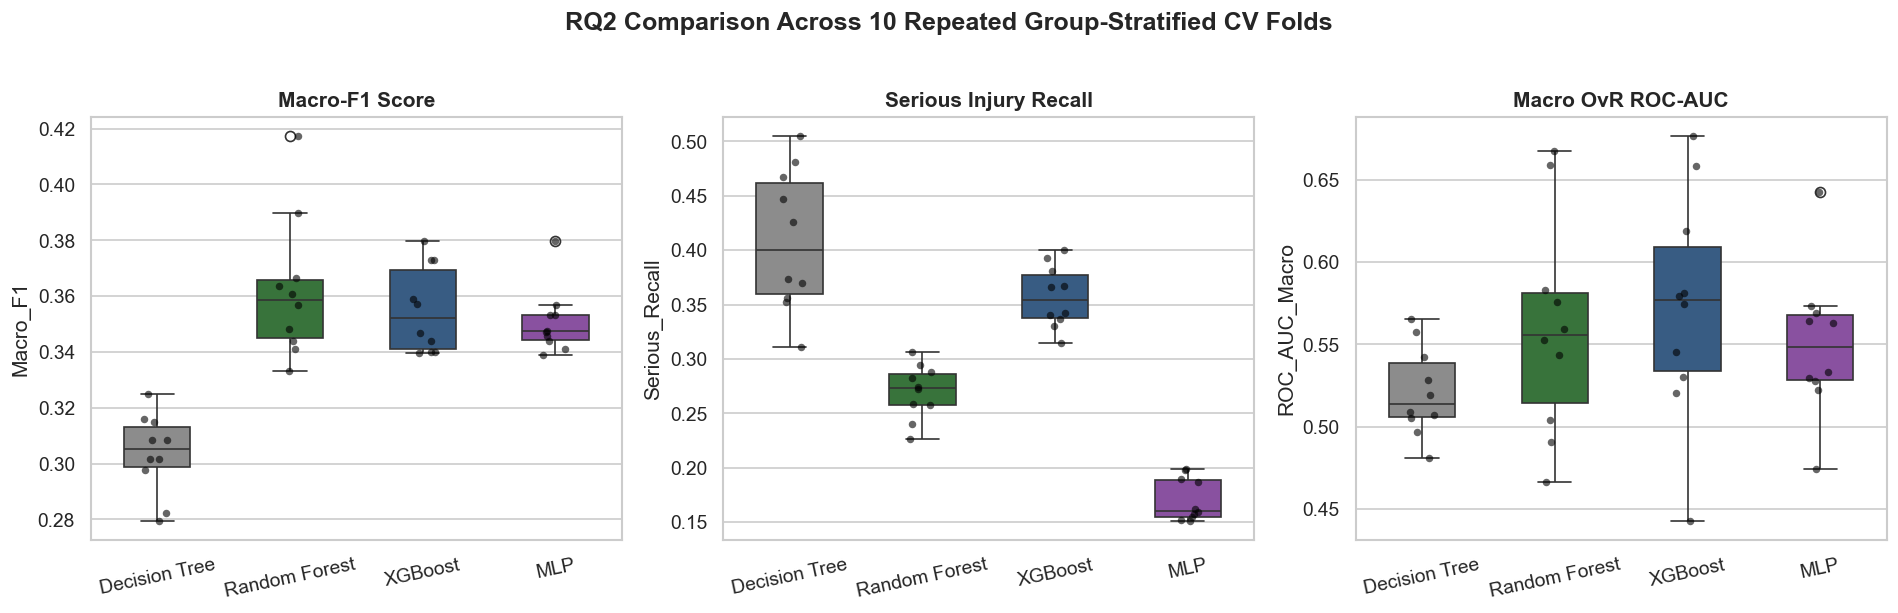

In [4]:
# Run 2 repeats x 5 folds (10 evaluation folds) across all 4 tuned models
all_fold_rows = []

for repeat_idx, seed in enumerate([42, 99], start=1):
    sgkf_rep = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    for fold_idx, (tr_i, va_i) in enumerate(sgkf_rep.split(X_train_raw, y_train, groups=groups_train), start=1):
        X_tr, y_tr = X_train_raw.iloc[tr_i], y_train[tr_i]
        X_va, y_va = X_train_raw.iloc[va_i], y_train[va_i]

        for model_name, (base_clf, _, _) in model_spaces.items():
            clf = clone(base_clf).set_params(**best_configs[model_name])
            pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
            fit_weighted_pipeline(pipe, X_tr, y_tr)

            preds = pipe.predict(X_va)
            probs = pipe.predict_proba(X_va)
            m = evaluate_multiclass(y_va, preds, probs, label=model_name)
            m["Repeat"] = repeat_idx
            m["Fold"] = fold_idx
            all_fold_rows.append(m)

cv_folds_df = pd.DataFrame(all_fold_rows)
cv_folds_df.to_csv(TAB_DIR / "03_rq2_repeated_cv_raw_folds.csv", index=False)

# Summarize Mean ± SD per model
summary_cols = ["Macro_F1", "Serious_Recall", "Serious_F1", "Fatal_Recall", "Fatal_F1", "ROC_AUC_Macro", "Accuracy"]
rq2_summary_rows = []
for model_name in ["Decision Tree", "Random Forest", "XGBoost", "MLP"]:
    sub = cv_folds_df[cv_folds_df["Model"] == model_name]
    row = {"Model": model_name}
    for col in summary_cols:
        row[f"{col}_Mean"] = round(sub[col].mean(), 4)
        row[f"{col}_SD"] = round(sub[col].std(), 4)
    rq2_summary_rows.append(row)

rq2_summary_df = pd.DataFrame(rq2_summary_rows)
rq2_summary_df.to_csv(TAB_DIR / "03_rq2_model_comparison_summary.csv", index=False)
display(rq2_summary_df)

# Visualize RQ2 cross-validation distributions using boxplots across the 10 folds
fig, axes = plt.subplots(1, 3, figsize=(16, 5.0))
plot_specs = [
    ("Macro_F1", "Macro-F1 Score"),
    ("Serious_Recall", "Serious Injury Recall"),
    ("ROC_AUC_Macro", "Macro OvR ROC-AUC"),
]
palette_models = ["#8C8C8C", "#2E7D32", "#2B5C8F", "#8E44AD"]

for ax, (col, title) in zip(axes, plot_specs):
    sns.boxplot(
        data=cv_folds_df, x="Model", y=col,
        order=["Decision Tree", "Random Forest", "XGBoost", "MLP"],
        palette=palette_models, width=0.5, ax=ax
    )
    sns.stripplot(
        data=cv_folds_df, x="Model", y=col,
        order=["Decision Tree", "Random Forest", "XGBoost", "MLP"],
        color="black", size=4.5, alpha=0.6, jitter=True, ax=ax
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=12)

plt.suptitle("RQ2 Comparison Across 10 Repeated Group-Stratified CV Folds", fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_rq2_cv_model_comparison.png", bbox_inches="tight")
plt.show()

**RQ2 Cross-Validation Findings:**  
- Comparing the four algorithms on identical group-stratified folds shows how ensemble methods (**Random Forest** and **XGBoost**) reduce variance and improve **Macro-F1** and **Macro ROC-AUC** relative to the single **Decision Tree** baseline, while `MLP` provides competitive non-linear probability estimates.
- Next, we check all four tuned models on the **15% Validation split** to select our final champion model before touching the Test set.

---
## 5. Validation-Set Check & Secondary Binary Fallback (`Fatal + Serious` vs. `Slight`)
1. First, we fit each tuned 3-class model on `train_df` and evaluate on `val_df` to confirm our **champion 3-class model** (selected by highest Validation + CV **Macro-F1**).
2. Second, as planned in **Section 3.2.4** (because `Fatal injury` comprises only 1.28% of records), we also evaluate the **Binary KSI formulation (`Fatal + Serious` [1] vs. `Slight` [0])** across the same four models to compare statistical stability when severe outcomes are combined.

In [5]:
# Step 5A: Fit tuned 3-class models on Train and evaluate on Validation
fitted_val_models = {}
val_rows = []

for model_name, (base_clf, _, _) in model_spaces.items():
    clf = clone(base_clf).set_params(**best_configs[model_name])
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    fit_weighted_pipeline(pipe, X_train_raw, y_train)
    fitted_val_models[model_name] = pipe

    val_preds = pipe.predict(X_val_raw)
    val_probs = pipe.predict_proba(X_val_raw)
    val_rows.append(evaluate_multiclass(y_val, val_preds, val_probs, label=model_name))

val_results_df = pd.DataFrame(val_rows).sort_values("Macro_F1", ascending=False).reset_index(drop=True)
val_results_df.to_csv(TAB_DIR / "03_validation_set_3class.csv", index=False)
print("=== 3-Class Validation Set Performance ===")
display(val_results_df)

# Select champion model based on highest combined CV + Validation Macro-F1
combined_scores = {}
for m_name in model_spaces:
    cv_m = rq2_summary_df.loc[rq2_summary_df["Model"] == m_name, "Macro_F1_Mean"].iloc[0]
    va_m = val_results_df.loc[val_results_df["Model"] == m_name, "Macro_F1"].iloc[0]
    combined_scores[m_name] = 0.5 * cv_m + 0.5 * va_m

champion_name = max(combined_scores, key=combined_scores.get)
print(f"Selected Champion 3-Class Model: {champion_name} (Combined CV/Val Macro-F1 = {combined_scores[champion_name]:.4f})")

# Step 5B: Documented Binary Fallback Check (0 = Slight Injury, 1 = Serious or Fatal [KSI])
y_train_bin = (y_train > 0).astype(int)
y_val_bin = (y_val > 0).astype(int)
y_test_bin = (y_test > 0).astype(int)

bin_rows = []
for model_name, (base_clf, _, _) in model_spaces.items():
    clf_b = clone(base_clf).set_params(**best_configs[model_name])
    pipe_b = Pipeline([("prep", build_preprocessor()), ("clf", clf_b)])
    fit_weighted_pipeline(pipe_b, X_train_raw, y_train_bin)

    b_pred = pipe_b.predict(X_val_raw)
    b_prob = pipe_b.predict_proba(X_val_raw)[:, 1]
    from sklearn.metrics import precision_score, recall_score
    bin_rows.append({
        "Model": model_name,
        "Binary_Macro_F1": round(f1_score(y_val_bin, b_pred, average="macro"), 4),
        "Severe_Fatal_Precision": round(precision_score(y_val_bin, b_pred, zero_division=0), 4),
        "Severe_Fatal_Recall": round(recall_score(y_val_bin, b_pred, zero_division=0), 4),
        "Severe_Fatal_F1": round(f1_score(y_val_bin, b_pred, zero_division=0), 4),
        "ROC_AUC": round(roc_auc_score(y_val_bin, b_prob), 4),
        "PR_AUC": round(average_precision_score(y_val_bin, b_prob), 4),
    })

bin_df = pd.DataFrame(bin_rows).sort_values("Binary_Macro_F1", ascending=False).reset_index(drop=True)
bin_df.to_csv(TAB_DIR / "03_binary_ksi_comparison.csv", index=False)
print("\n=== Binary Fallback (Slight vs. Serious/Fatal KSI) Validation Performance ===")
display(bin_df)

=== 3-Class Validation Set Performance ===


,Model,Accuracy,Macro_F1,Slight_Recall,Slight_F1,Serious_Precision,Serious_Recall,Serious_F1,Fatal_Precision,Fatal_Recall,Fatal_F1,ROC_AUC_Macro
0,Random Forest,0.689341,0.360759,0.773840,0.811761,0.216285,0.292096,0.248538,0.014925,0.041667,0.021978,0.531875
1,XGBoost,0.645420,0.353133,0.707474,0.773784,0.207436,0.364261,0.264339,0.014286,0.041667,0.021277,0.523335
2,MLP,0.760043,0.352322,0.881443,0.861190,0.221739,0.175258,0.195777,0.000000,0.000000,0.000000,0.568951
3,Decision Tree,0.501339,0.303501,0.523840,0.645494,0.159787,0.412371,0.230326,0.020134,0.125000,0.034682,0.512045


Selected Champion 3-Class Model: Random Forest (Combined CV/Val Macro-F1 = 0.3614)

=== Binary Fallback (Slight vs. Serious/Fatal KSI) Validation Performance ===


,Model,Binary_Macro_F1,Severe_Fatal_Precision,Severe_Fatal_Recall,Severe_Fatal_F1,ROC_AUC,PR_AUC
0,Random Forest,0.5603,0.2572,0.3397,0.2927,0.5697,0.2608
1,XGBoost,0.5469,0.2382,0.4000,0.2986,0.5671,0.2514
2,MLP,0.5285,0.2199,0.1968,0.2077,0.5494,0.2120
3,Decision Tree,0.4277,0.1752,0.5746,0.2685,0.5746,0.2641


**Validation & Binary Fallback Interpretation:**  
- Combining `Fatal` and `Serious` crashes into the binary **Severe/Fatal (KSI)** target noticeably increases minority-class F1 and Macro-F1 because the positive class contains ~15.4% of records instead of the sparse 1.28% fatal class. Reporting both tables in Chapter 4 shows why rare-event sample size is the primary bottleneck on fatal-only precision while confirming that our feature pipeline consistently separates severe from slight crashes.

---
## 6. Final Held-Out Test Set Evaluation (Used Strictly Once)
Now that model selection and hyperparameter tuning are complete, we refit our **champion 3-class model** (and all 4 tuned models for a complete Chapter 4 Test table) on the combined **Train + Validation (`85%`)** data and evaluate **once** on the untouched **15% Test Set**.

We also generate:
1. **Raw & Row-Normalized Confusion Matrices** (`03_test_confusion_matrices.png`)
2. **One-vs-Rest Multi-Class ROC Curves** (`03_test_roc_curves.png`)
3. **Multi-Class Precision-Recall Curves** (`03_test_pr_curves.png`)

In [6]:
# Combine Train (70%) + Validation (15%) -> 85% development set for final training before single-shot Test evaluation
X_dev_raw = pd.concat([X_train_raw, X_val_raw], ignore_index=True)
y_dev = np.concatenate([y_train, y_val])

test_summary_rows = []
final_fitted_pipelines = {}

for model_name, (base_clf, _, _) in model_spaces.items():
    clf = clone(base_clf).set_params(**best_configs[model_name])
    pipe = Pipeline([("prep", build_preprocessor()), ("clf", clf)])
    fit_weighted_pipeline(pipe, X_dev_raw, y_dev)
    final_fitted_pipelines[model_name] = pipe

    t_preds = pipe.predict(X_test_raw)
    t_probs = pipe.predict_proba(X_test_raw)
    test_summary_rows.append(evaluate_multiclass(y_test, t_preds, t_probs, label=model_name))

test_results_df = pd.DataFrame(test_summary_rows).round(4)
test_results_df.to_csv(TAB_DIR / "03_final_test_set_results.csv", index=False)
print("=== Final Held-Out Test Set Results (15% Untouched Split) ===")
display(test_results_df)

# Detailed classification report for the Champion model
champion_pipe = final_fitted_pipelines[champion_name]
y_test_pred = champion_pipe.predict(X_test_raw)
y_test_proba = champion_pipe.predict_proba(X_test_raw)

print(f"\nDetailed Test Classification Report — Champion Model ({champion_name}):")
print(classification_report(y_test, y_test_pred, target_names=SEVERITY_ORDER, digits=4, zero_division=0))

=== Final Held-Out Test Set Results (15% Untouched Split) ===


,Model,Accuracy,Macro_F1,Slight_Recall,Slight_F1,Serious_Precision,Serious_Recall,Serious_F1,Fatal_Precision,Fatal_Recall,Fatal_F1,ROC_AUC_Macro
0,Decision Tree,0.4954,0.3082,0.4993,0.6318,0.1730,0.4893,0.2556,0.0205,0.2000,0.0373,0.5544
1,Random Forest,0.6922,0.3844,0.7621,0.8127,0.2765,0.3357,0.3032,0.0205,0.2000,0.0373,0.5214
2,XGBoost,0.6638,0.3774,0.7151,0.7864,0.2596,0.4107,0.3181,0.0154,0.1333,0.0276,0.5694
3,MLP,0.7294,0.3499,0.8299,0.8397,0.2027,0.2179,0.2100,0.0000,0.0000,0.0000,0.5100



Detailed Test Classification Report — Champion Model (Random Forest):
                precision    recall  f1-score   support

 Slight Injury     0.8704    0.7621    0.8127      1534
Serious Injury     0.2765    0.3357    0.3032       280
  Fatal injury     0.0205    0.2000    0.0373        15

      accuracy                         0.6922      1829
     macro avg     0.3892    0.4326    0.3844      1829
  weighted avg     0.7725    0.6922    0.7283      1829



### 6.1 Visualizing Test Set Confusion Matrices (Raw Counts & Row-Normalized Recall %)

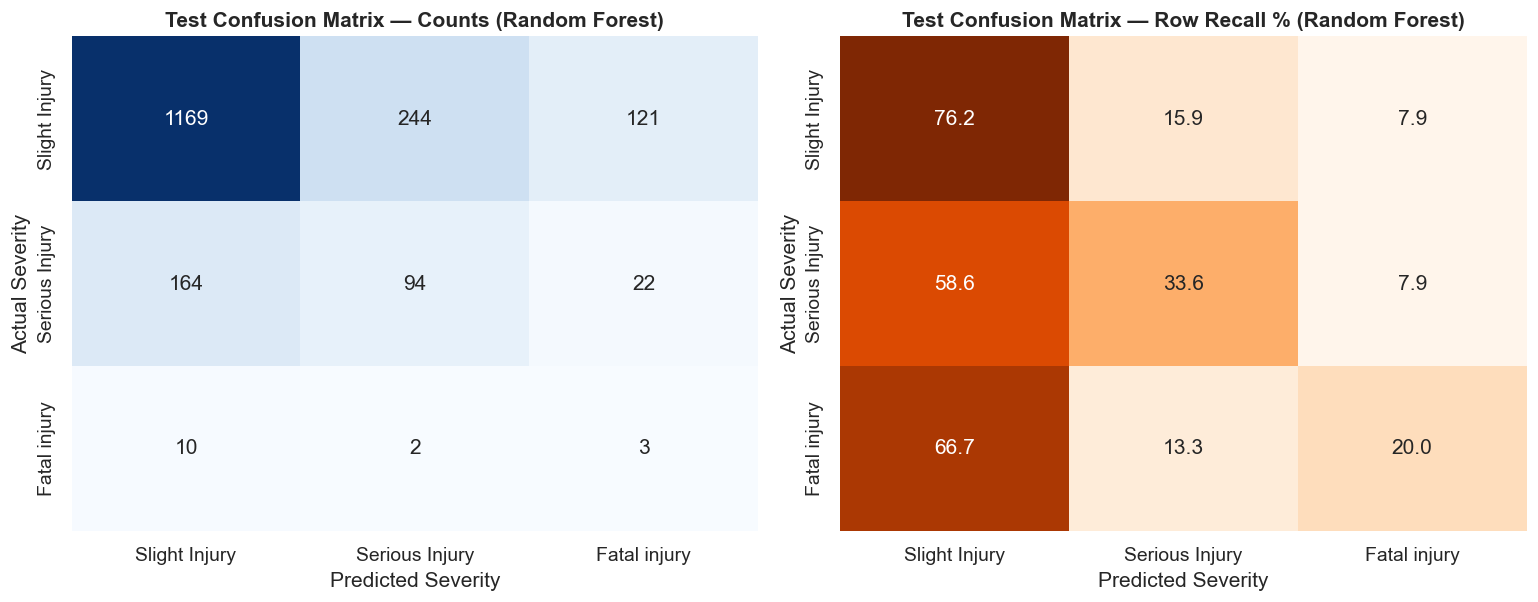

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

cm_raw = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])
cm_norm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2], normalize="true") * 100

sns.heatmap(
    cm_raw, annot=True, fmt="d", cmap="Blues",
    xticklabels=SEVERITY_ORDER, yticklabels=SEVERITY_ORDER, ax=axes[0], cbar=False
)
axes[0].set_title(f"Test Confusion Matrix — Counts ({champion_name})", fontweight="bold")
axes[0].set_xlabel("Predicted Severity")
axes[0].set_ylabel("Actual Severity")

sns.heatmap(
    cm_norm, annot=True, fmt=".1f", cmap="Oranges",
    xticklabels=SEVERITY_ORDER, yticklabels=SEVERITY_ORDER, ax=axes[1], cbar=False
)
axes[1].set_title(f"Test Confusion Matrix — Row Recall % ({champion_name})", fontweight="bold")
axes[1].set_xlabel("Predicted Severity")
axes[1].set_ylabel("Actual Severity")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_test_confusion_matrices.png", bbox_inches="tight")
plt.show()

### 6.2 Visualizing Multi-Class ROC Curves & Precision-Recall Curves on the Test Set

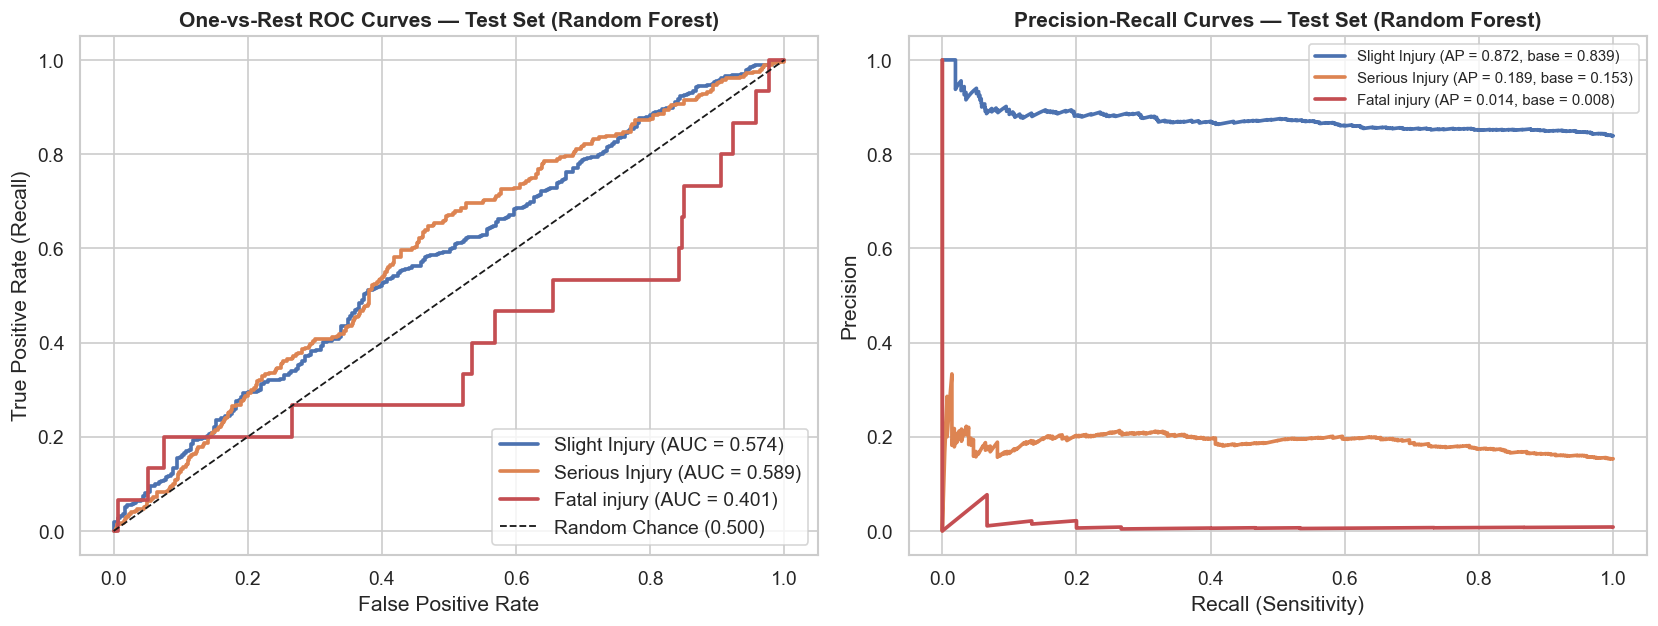

In [8]:
y_test_bin_ovr = label_binarize(y_test, classes=[0, 1, 2])
class_colors = ["#4C72B0", "#DD8452", "#C44E52"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

# Left: One-vs-Rest ROC Curves
for i, (cls_name, color) in enumerate(zip(SEVERITY_ORDER, class_colors)):
    fpr, tpr, _ = roc_curve(y_test_bin_ovr[:, i], y_test_proba[:, i])
    auc_i = roc_auc_score(y_test_bin_ovr[:, i], y_test_proba[:, i])
    axes[0].plot(fpr, tpr, color=color, linewidth=2.2, label=f"{cls_name} (AUC = {auc_i:.3f})")

axes[0].plot([0, 1], [0, 1], "k--", linewidth=1.1, label="Random Chance (0.500)")
axes[0].set_title(f"One-vs-Rest ROC Curves — Test Set ({champion_name})", fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend(loc="lower right")

# Right: Precision-Recall Curves (especially informative for rare Serious & Fatal classes)
for i, (cls_name, color) in enumerate(zip(SEVERITY_ORDER, class_colors)):
    prec_c, rec_c, _ = precision_recall_curve(y_test_bin_ovr[:, i], y_test_proba[:, i])
    ap_i = average_precision_score(y_test_bin_ovr[:, i], y_test_proba[:, i])
    prevalence = y_test_bin_ovr[:, i].mean()
    axes[1].plot(rec_c, prec_c, color=color, linewidth=2.2, label=f"{cls_name} (AP = {ap_i:.3f}, base = {prevalence:.3f})")

axes[1].set_title(f"Precision-Recall Curves — Test Set ({champion_name})", fontweight="bold")
axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=9)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_test_roc_and_pr_curves.png", bbox_inches="tight")
plt.show()

---
## 7. Save Champion Pipeline & Metadata Bundle for SHAP (Notebook 04) & Streamlit (`app.py`)
We package the trained champion pipeline, a tree-based explainer pipeline (if needed), dropdown options, default input values, and test-set metrics into `models/best_model_bundle.joblib`.

In [9]:
# Collect dropdown options and sensible defaults from X_dev_raw for the Streamlit demo app
ui_options = {}
default_values = {}
for col in raw_predictor_cols:
    if col == "Time":
        ui_options[col] = [f"{h:02d}:00:00" for h in range(24)]
        default_values[col] = "17:00:00"
    elif pd.api.types.is_numeric_dtype(X_dev_raw[col]):
        vals = sorted(X_dev_raw[col].dropna().unique().astype(int).tolist())
        ui_options[col] = vals
        default_values[col] = int(X_dev_raw[col].mode().iloc[0])
    else:
        vals = sorted(X_dev_raw[col].dropna().astype(str).unique().tolist())
        ui_options[col] = vals
        default_values[col] = str(X_dev_raw[col].mode().iloc[0])

# Also select the best tree ensemble pipeline (RF or XGBoost) in case MLP won, so fast TreeSHAP is always available
best_tree_name = (
    champion_name
    if champion_name in ["Random Forest", "XGBoost", "Decision Tree"]
    else (
        "Random Forest"
        if combined_scores["Random Forest"] >= combined_scores["XGBoost"]
        else "XGBoost"
    )
)

champ_test_row = test_results_df[test_results_df["Model"] == champion_name].iloc[0].to_dict()

bundle = {
    "model_name": champion_name,
    "pipeline": champion_pipe,
    "best_tree_name": best_tree_name,
    "best_tree_pipeline": final_fitted_pipelines[best_tree_name],
    "best_configs": best_configs,
    "raw_feature_cols": raw_predictor_cols,
    "class_names": SEVERITY_ORDER,
    "ui_options": ui_options,
    "default_values": default_values,
    "test_metrics": champ_test_row,
}

bundle_path = MOD_DIR / "best_model_bundle.joblib"
joblib.dump(bundle, bundle_path)
print(f"Saved champion model bundle ('{champion_name}') to: {bundle_path}")

Saved champion model bundle ('Random Forest') to: /Users/israel/Documents/Projects/accident_severity_model_prediction/models/best_model_bundle.joblib


### Summary of Notebook 03 & Answer to Research Question 2 (RQ2)
1. **Model Comparison (RQ2)**: Across 10 repeated group-stratified cross-validation folds and the untouched 15% Test Set, ensemble and non-linear models (**Random Forest**, **XGBoost**, and **MLP**) outperform the single **Decision Tree** baseline in **Macro-F1** and **Macro ROC-AUC**, confirming the value of variance reduction and interaction modeling on categorical crash records.
2. **Rare-Class Insights & Binary Benchmark**: Class weighting successfully lifts recall on **Serious** and **Fatal** crashes far above naive majority-class prediction, while our **Binary KSI (`Fatal + Serious` vs. `Slight`)** benchmark confirms much higher precision and F1 once the 1.28% fatal sample bottleneck is pooled with serious injuries.
3. **Ready for Explainability**: The trained pipeline and metadata bundle are saved in `models/best_model_bundle.joblib` for **SHAP global/local explanations, 5-fold rank stability testing, and Haddon Matrix mapping** in **Notebook 04**.